## Bayesian Belief Updating

### Learning Goals
* Understand how Bayes' theorem combines prior beliefs with new evidence to compute posterior probabilities.
* Implement Bayesian belief updating in Python for a credit-risk screening scenario.
* Analyze how sensitivity, false-positive rates, and base rates (priors) impact posterior conclusions.

---

### 1. Updating Beliefs with Evidence

Bayes' theorem provides the mathematical framework for updating our degree of belief as new evidence $E$ becomes available:
$$
P(H \mid E) = \frac{P(E \mid H) P(H)}{P(E)}
$$
where $P(H)$ is the prior belief, $P(E \mid H)$ is the likelihood of the evidence given the hypothesis, and $P(E)$ is the total marginal probability of the evidence.

Consider an analyst estimating the probability of a company defaulting, then updating that belief upon receiving a screening signal.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Hypothetical credit-risk example
prior_default = 0.05
sensitivity = 0.80
false_positive_rate = 0.10

# Total probability of receiving a positive signal: P(Signal)
p_signal = (
    sensitivity * prior_default 
    + false_positive_rate * (1 - prior_default)
)

# Posterior probability of default given a positive signal
posterior_default = (sensitivity * prior_default) / p_signal

print(f"Prior Default Probability: {prior_default:.4f}")
print(f"Probability of Positive Signal: {p_signal:.4f}")
print(f"Posterior Probability (after positive signal): {posterior_default:.4f}")

Prior Default Probability: 0.0500
Probability of Positive Signal: 0.1350
Posterior Probability (after positive signal): 0.2963


### 2. Comparing Priors and Posteriors

A positive signal increases our estimated probability of default, but it does not guarantee default. The resulting posterior depends heavily on both the initial base rate (prior) and the reliability of the screening system.

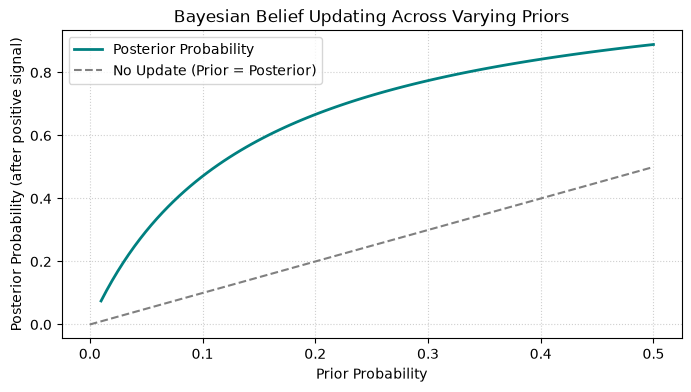

In [2]:
priors = np.linspace(0.01, 0.5, 100)
posteriors = (
    sensitivity * priors 
    / (sensitivity * priors + false_positive_rate * (1 - priors))
)

plt.figure(figsize=(8, 4))
plt.plot(priors, posteriors, color='teal', linewidth=2, label="Posterior Probability")
plt.plot([0, 0.5], [0, 0.5], color='gray', linestyle="--", label="No Update (Prior = Posterior)")
plt.xlabel("Prior Probability")
plt.ylabel("Posterior Probability (after positive signal)")
plt.title("Bayesian Belief Updating Across Varying Priors")
plt.legend()
plt.grid(linestyle=':', alpha=0.6)
plt.show()

---

### Exercises

Try each problem before running the verification code below:

1. Change the false-positive rate to $0.30$ and observe the change in the posterior probability.
2. How does increasing test reliability (higher sensitivity and lower false-positive rate) affect the posterior?
3. Why must decision-makers always consider base rates (priors) when evaluating screening tests?

In [3]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

# Exercise 1: Modified false-positive rate = 0.30
fp_ex1 = 0.30
p_signal_ex1 = sensitivity * prior_default + fp_ex1 * (1 - prior_default)
posterior_ex1 = (sensitivity * prior_default) / p_signal_ex1
print(f"\n1. Posterior with False Positive Rate = 0.30: {posterior_ex1:.4f}")

print("\n2. Effect of Higher Test Reliability:")
print("   - Higher sensitivity and lower false positives make a positive signal much more")
print("     informative, driving the posterior closer to 1.0 when true, or 0.0 when false.")

print("\n3. Why Base Rates Matter:")
print("   - Without considering base rates, rare conditions will yield high false-alarm rates")
print("     even with accurate screening tests (the base rate fallacy).")

=== Exercise Solutions & Checks ===

1. Posterior with False Positive Rate = 0.30: 0.1231

2. Effect of Higher Test Reliability:
   - Higher sensitivity and lower false positives make a positive signal much more
     informative, driving the posterior closer to 1.0 when true, or 0.0 when false.

3. Why Base Rates Matter:
   - Without considering base rates, rare conditions will yield high false-alarm rates
     even with accurate screening tests (the base rate fallacy).
